# 0. Outline

⭐⭐ **I have translated all the Chinese into English in every line of code in the notebook if the code contains Chinese, so please don't worry that you can't read the entire notebook well because you can't understand Chinese.** ⭐⭐

In order to fully exploit and demonstrate the outstanding potential of Gemma in the field of multilingual processing, I adopted the Gemma-2-9b-it model and fine-tuned it, with a special focus on the unique and challenging language domain of **Ancient Chinese (Simplified) and Chinese culture**. As a result of this series of efforts, Gemma has achieved impressive results on the [ACLUE](https://github.com/isen-zhang/ACLUE/blob/main/README_EN.md) Leaderboard, even surpassing ChatGPT's score.

| model     | Lexical | Syntactic | Semantic | Inference | Knowledge |
|-----------|---------|-----------|----------|-----------|-----------|
| [ChatGPT](https://openai.com/chatgpt)                     |   34.53   |   43.00   |   36.40   |   **41.23**   |   33.61   |
| **gemma-2-9b-sft-lora**                                   |   **44.13**   | **58.20** |   **45.30**   |   38.43   | **39.60** |

Key points contained in this notebook:
1. **🔍(Fix Problems) How to get Gemma2 to get rid of incoherences problems in Chinese (Simplified).** Gemma2 easily outputs results mixed with English when the input is Chinese. This can be a common problem with polylingual models, which is that the results generated are not consistent with the queries they are received.
2. **🧑‍🎓(Finetune) Make Gemma2 become an expert in ancient Chinese.** Classical Chinese experts need to have accurate and reliable results in ancient Chinese literature, ancient Chinese poetry, ancient Chinese couplets and ancient Chinese idioms.
3. **🎉(Large dataset) This project provides a dataset of 252k focusing on ancient Chinese collected and created by me.**
4. **📖(RAG) How to use RAG to remove model hallucinations and get accurate results. FYI, with a extra RAG dataset of 30k ancient Chinese idioms.**
5. **💡(Few-shot) How to use few-shot prompting in ancient Chinese study.**
6. **🚀(Quantization) How to implement LoRA to train models and load models using quantization techniques.**
7. **💪(Robustness) Robustness testing of trained Gemma2**: To observe whether the trained model is robust, we tested inputs in multiple languages.

# 1. Introduction



## 1.1. Application of LLM in ancient Chinese and Chinese culture
The application of large models in ancient Chinese is mainly reflected in the Words Interpretation, Ancient Words Translation, Sentence Reading Punctuation, Dictionary Analysis, Literature Classification, and Linguistic Studies. Here's a closer look at these applications:

**Words Interpretation**
        Large models are able to accurately interpret the meaning of words in ancient Chinese, which is essential for understanding ancient texts. 

**Ancient Words Translation**
        The large model can accurately translate classical Chinese into modern Chinese, helping modern people better understand ancient documents, facilitating literary creation and academic research.

**Linguistic Studies**
    The large model can also be used to study the comparison between ancient Chinese and modern Chinese, other ancient languages, and foreign languages. Through comparison and analysis, researchers are able to reveal the commonalities and differences between different languages, providing new perspectives and methods for linguistic research.

[![ancient-chinese-expert.png](https://i.postimg.cc/Z5nGt2Fq/ancient-chinese-expert.png)](https://postimg.cc/FYtW0P6t)


## 1.2. Orginal Gemma's Chinese ability

Let's try Gemma-2's performance in Chinese and Ancient Chinese.

In [1]:
# firstly, install necessary package
!pip install peft -q
!pip install -U bitsandbytes -q
!pip install FlagEmbedding==1.1.2 -q
!pip install faiss-cpu -q

In [2]:
# Import necessary libraries
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM  # Import tokenizer and model
import os

os.environ["CUDA_VISIBLE_DEVICES"] = '0,1'  # Set the training devices
# 
model_path = "/kaggle/input/gemma-2/transformers/gemma-2-2b-it/2"

model = AutoModelForCausalLM.from_pretrained(model_path, # Load the pre-trained model with specified configurations
                                             device_map='auto',# 'device_map' automatically maps the model to available devices
                                             torch_dtype=torch.float16) # 'dtype' specifies the data type for the model's weights and tensors, here using torch.float16 for efficiency

# Load the tokenizer that corresponds to the pre-trained model
tokenizer = AutoTokenizer.from_pretrained(model_path)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

In [3]:
# Firstly, we need to transfer the input text into Gemma formatting
def get_text_in_gemma_format(text):
    '''
    Gemma formatting:
    ```
    <start_of_turn>user
    knock knock<end_of_turn>
    <start_of_turn>model
    who is there<end_of_turn>
    ```
    
    Rel: https://ai.google.dev/gemma/docs/formatting
    '''
    messages = [{'role': 'user', 'content': text}]
    gemma_formatting_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    return gemma_formatting_text

# Secondly, we build a generate pipeline.
def get_gemma_output(tokenizer, text, model):
    model_inputs = tokenizer([text], return_tensors="pt").to(model.device) # We need transfer charaters into input_ids.
    generated_ids = model.generate(
        **model_inputs,
        max_new_tokens=256, # max_new_tokens specifies the maximum number of new tokens the model can generate.
        do_sample=False, # do_sample: model will randomly sample from the predicted token distribution, which can lead to more varied and often more interesting generations.
        temperature=-1.0, # temperature controls the randomness of the sampling process.
        top_p=0.9, # top_p: alternative to temperature scaling that controls diversity by first considering the smallest possible set of candidates whose cumulative probability mass exceeds the top_p threshold.
        top_k=40, # top_k limits the number of highest probability tokens considered for sampling to n tokens.
    )
    generated_ids = [
        output_ids[len(input_ids):] for input_ids, output_ids in zip(model_inputs.input_ids, generated_ids) # We only care new words that model generate, there we need output_ids after input_ids
    ]
    generated_text = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

### 1.2.1. Ancient Chinese literature translation

In [4]:
text = "无始曰： 弗知之深而知之浅，弗知内而知之外，弗知精而知之粗。\n帮我翻译成现代文" # the instruction in English: 【The Ancient Chinese】\n Translate this sentence into modern Chinese.
gemma_formatting_text = get_text_in_gemma_format(text)
print(f'**********gemma_formatting_text**********\n {gemma_formatting_text}\n')
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, model)
print('\n**********generated_text**********\n')
print(generated_text)

**********gemma_formatting_text**********
 <bos><start_of_turn>user
无始曰： 弗知之深而知之浅，弗知内而知之外，弗知精而知之粗。
帮我翻译成现代文<end_of_turn>
<start_of_turn>model




/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `-1.0` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `40` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



**********generated_text**********

This is a classic Chinese proverb, and it's a bit tricky to translate directly. Here's a breakdown and a few possible translations:

**Literal Translation:**

* **弗知之深而知之浅:**  I don't know its depth, but I know its shallowness.
* **弗知内而知之外:** I don't know its inner workings, but I know its outer appearance.
* **弗知精而知之粗:** I don't know its fine details, but I know its general nature.

**Modern Translations:**

Here are a few ways to translate this proverb into modern English, capturing its essence:

* **"I don't know its true depth, but I know its superficiality."** (This emphasizes the contrast between knowing the surface and the deeper meaning.)
* **"I don't understand its complexities, but I see its obvious features."** (This focuses on the lack of understanding of the inner workings.)
* **"I don't know its intricacies, but I grasp its basic nature."** (This highlights the lack of knowledge about the fine details but the understanding of the overa

### 1.2.2. Ancient Chinese poems

In [5]:
text = "以夏天为主题写一首诗" # the instruction in English: Topic: Summer. Make a Ancient Chinese Poetry
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, model)
print('\n**********generated_text**********\n')
print(generated_text)


**********generated_text**********

Sun-drenched days, a golden haze,
Heat shimmers on the summer days.
Cicadas sing their drowsy tune,
As lazy breezes blow the afternoon.

Fields of green, a vibrant hue,
Where wildflowers bloom, a vibrant view.
Children laugh, their voices bright,
Playing games beneath the sun's warm light.

Ice cream melts, a sweet delight,
As fireflies dance in the fading light.
The scent of honeysuckle fills the air,
A summer's night, beyond compare.

Barefoot steps on warm, soft sand,
A gentle wave, a helping hand.
The ocean's roar, a calming sound,
As summer's magic all around.

So let us bask in this golden glow,
And let the summer's spirit flow.
For in its warmth, we find release,
A time of joy, a time of peace. 



### 1.2.3. Chinese couplet 

In [6]:
text = "上联：速造林，快育林，广护林，绿茵似海\n下联：" # the instruction in English: Upper Scroll of couplet: 【Neatly arranged ancient Chinese Couplet】\n Lower Scroll of couplet:
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, model)
print('\n**********generated_text**********\n')
print(generated_text)


**********generated_text**********

下联：**绿叶飘零，枝繁叶茂，鸟鸣花香，清风拂面** 


**解释：**

* **上联：** 
    * **速造林：**  指快速建立森林。
    * **快育林：** 指森林快速生长。
    * **广护林：** 指保护森林。
    * **绿茵似海：**  形容森林茂盛，如同一片绿色的海洋。

* **下联：** 
    * **绿叶飘零：**  形容树叶茂盛，飘落。
    * **枝繁叶茂：**  形容树木繁茂，枝繁叶茂。
    * **鸟鸣花香：**  形容森林生机勃勃，鸟鸣花香。
    * **清风拂面：**  形容森林清新，清风拂面。


这两联联想在一起，表达了森林的美丽和生机勃勃，以及人们对森林的保护和珍惜。 





### 1.2.4. Chinese idioms

In [7]:
text = "螳螂捕蝉，黄雀在后 是什么意思？" # the instruction in English: Idiom Definition: 【The Idiom】\n Meaning:
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, model)
print('\n**********generated_text**********\n')
print(generated_text)


**********generated_text**********

"螳螂捕蝉，黄雀在后" is a Chinese proverb that means:

**"The mantis catches the cicada, but the sparrow is behind."**

**Meaning:**

This proverb highlights the concept of **opportunism and the interconnectedness of nature.** It illustrates that:

* **The mantis, a small insect, catches the cicada, a larger insect, which is vulnerable and easily caught.** This represents the idea that those who are seemingly powerful or dominant can be easily defeated by those who are more cunning or opportunistic.
* **The sparrow, a bird, is able to take advantage of the situation.** It is not directly involved in the mantis's attack, but it benefits from the mantis's success. This symbolizes the idea that even seemingly insignificant actions can have unexpected consequences and that there are always opportunities for those who are prepared to take advantage of them.

**The proverb is often used to illustrate:**

* **The importance of being aware of your surroundings and a

## 1.3. Conclusion of Orginal Gemma-2 2b

Through the above instructions and outputs about ancient Chinese and Chinese culture, we find that the model has the following problems：

- **The consistency of the Chinese language is weak.😕**, the input instructions are Chinese, and the output results of the model are often mixed with English.
- **The comprehension ability of ancient Chinese is relatively weak.😭**, and the results obtained by not being able to translate are relatively poor.
- **The ability to generate ancient Chinese poems and traditional Chinese couplets is relatively poor.😥** Both ancient Chinese poems and couplets require each line to have the same part of speech, the same structure, and the same theme, and it is clear that Gemma2-2b is not yet capable of meeting this requirement.

Next, we will enhance Gemma's ability in ancient Chinese through fine-tuning.

# 2. Training Data Choice and Collection

If we want to improve Gemma's ability in ancient Chinese, it is natural to collect some datasets related to ancient Chinese. Unfortunately, there are few studies on the application of LLMs in ancient Chinese, so there are no datasets on the theme of ancient Chinese.
So, I thought of two ways to build our dataset:
1. Collect the part of the dataset of ancient Chinese from the open source Chinese dataset.
2. Build a new dataset based on an existing dataset by modifying the instructions and outputs.

There are a large number of Chinese datasets, and most of them have no samples of ancient Chinese. It is also not easy to construct a new dataset on the basis of the need to maximize the quality of the original dataset. Therefore, I spent almost 80% of my time on collecting and building the [dataset](https://www.kaggle.com/datasets/judith007/ancient-chinese-data-by-shiner), and finally **I collected about 251k ancient Chinese samples in this [dataset](https://www.kaggle.com/datasets/judith007/ancient-chinese-data-by-shiner)**. I uploaded this dataset to Kaggle and [Hugging Face](https://huggingface.co/datasets/TroyeML/Ancient_Chinese_Study_252k), feel free to use them 😁. 

Let's check the instruction length of this datasets

## 2.1. Collect ancient Chinese data from open source dataset

In [8]:
# The datasets I collect are mainly from two publicly available datasets: FireFly and COIG-CQIA. 
# FireFly： https://huggingface.co/datasets/YeungNLP/firefly-train-1.1M
# COIG-CQIA： https://huggingface.co/datasets/m-a-p/COIG-CQIA
# Kudos to the efforts of their researchers.
from datasets import load_dataset
data_path = "/kaggle/input/ancient-chinese-data-by-shiner/ancient_chinese_full.json"
dataset = load_dataset("json", data_files=data_path, split="train")

# FireFly Ancient Chinese data:
firefly_ancient_data_sample = ''
for i in range(len(dataset)):
    if 'firefly' in dataset[i]['source']:
        firefly_ancient_data_sample = dataset[i]
        break

print(firefly_ancient_data_sample)

Generating train split: 0 examples [00:00, ? examples/s]

{'instruction': '写诗：\n诗人：戴亨\n标题：题运使卢同年抱孙画屏十二首 其九 喜雨图', 'input': '', 'output': '滦水不上天，旱魃形狰狞。小民惧无岁，嚣然遂不宁。抚之失其道，何以销未萌。奉诏起循吏，精祷格皇灵。化雨应时来，枯禾尽回生。发粟宥其愚，众庶歌欢腾。天人相感召，斯理洵可凭。', 'source': 'firefly_AncientPoem'}


In [9]:
# COIG Ancient Chinese data:
coig_ancient_data_sample = ''
for i in range(len(dataset)):
    if 'COIG' in dataset[i]['source']:
        coig_ancient_data_sample = dataset[i]
        break

print(coig_ancient_data_sample)

{'instruction': '暗度陈仓\n成语释义：', 'input': '', 'output': '指正面迷惑敌人，而从侧翼进行突然袭击。亦比喻暗中进行活动。陈仓，古县名，在今陕西省宝鸡市东，为通向汉中的交通孔道。\n成语出处：《史记·高祖本纪》……项王使卒三万人从，楚与诸侯之慕从者数万人，从杜南入蚀中。去辄烧绝栈道，以备诸侯盗兵袭之，亦示项羽无东意……八月，汉王用韩信之计，从故道还，袭雍王章邯—迎击汉陈仓，雍兵败，…', 'source': 'COIG_中国传统文化_成语'}


If you are interesting how I get the ancient Chinese samples from these datasets, you are welcome to check my another [notebook](https://www.kaggle.com/code/judith007/ancient-chinese-data-create).

## 2.2. Self-made dataset (CoT dataset)

As a native English speaker, when you look at an ancient Chinese sentence,📖 you can't read it, so you decide copy and paste the sentence into the translation software and translate it into English,🔍 and at this time, you will find that the English translated from ancient Chinese is a little strange and the sentence does not make sense.😕 When you want to translate English into ancient Chinese, you will also find it difficult to find an effective way to implement it.😭


I found a very interesting phenomenon: no matter what translator you use, translating ancient Chinese into English is prone to some errors. And translations from English to ancient Chinese are almost non-existent.
So I hope to solve this problem by constructing such a dataset so that the large model can have this ability. This is because most translation software is not optimized for ancient Chinese. 

This makes it difficult for everyone to understand Chinese culture and ancient Chinese. I hope to lower the threshold for people in English-speaking countries to understand Chinese culture and ancient Chinese through LLM strategy.☺️☺️☺️


This dataset https://www.kaggle.com/datasets/judith007/ancient-chinese-english-translate/data I constructed myself actually constructs a new task related to ancient Chinese: the task of **translating ancient Chinese and English to and from each other**.🤓

### 2.2.2. How I created this dataset

In [10]:
# In order to carry out the task of translating ancient Chinese and English to and from each other, we need to prepare a dataset of translation from ancient Chinese to modern Chinese.
sample_datasets = [
{'instruction': '但斗筲之人，既得伏奏帷扆，便欲诡竞求进，不论国之大体，心存明恕；惟务吹毛求疵，擘肌分理，以深刻为能，以绳逐为务。\n翻译成现代文：',
  'input': '',
  'output': '但是那些才短识浅气量狭小的人，既能靠近您，向您启奏，便想骗得您的信任，争相飞黄腾达，而不顾国家大局，不能心存宽恕，只一味地吹毛求疵，擘肌分理，过分苛细，以严酷为能干，把纠举别人过错并且呵斥驱逐人看成是自己的任务。'},
{'instruction': '但是那些才短识浅气量狭小的人，既能靠近您，向您启奏，便想骗得您的信任，争相飞黄腾达，而不顾国家大局，不能心存宽恕，只一味地吹毛求疵，擘肌分理，过分苛细，以严酷为能干，把纠举别人过错并且呵斥驱逐人看成是自己的任务。\n把这句话翻译成文言文：',
  'input': '',
  'output': '但斗筲之人，既得伏奏帷扆，便欲诡竞求进，不论国之大体，心存明恕；惟务吹毛求疵，擘肌分理，以深刻为能，以绳逐为务。'}
 ]
output_to_eng = sample_datasets[:1]
input_to_eng = sample_datasets[1:]
# It is necessary to translate modern Chinese into English as the output of the large model needs to be predicted. 
# Because modern translation into English is very accurate, feel free to use any of the translation APIs to do this.

def translate_text(chinese_text):
    '''
    This is a demo of translate Function, please use any translate API by your self.
    '''
    print('*****This is a demo of translate Function, please use any translate API by your self.*****')
    translated_text = '''But these insignificant people, once they have the opportunity to make reports behind the scenes, will start to compete for advancement by trickery, without considering the overall interests of the country or being forgiving in their hearts. They only seek to nitpick, analyze the details, and take profundity as their ability and strictness as their goal.'''
    return translated_text
    
translate_text(output_to_eng[0]['output'])

*****This is a demo of translate Function, please use any translate API by your self.*****


'But these insignificant people, once they have the opportunity to make reports behind the scenes, will start to compete for advancement by trickery, without considering the overall interests of the country or being forgiving in their hearts. They only seek to nitpick, analyze the details, and take profundity as their ability and strictness as their goal.'

In [11]:
# Then let's modify the instruction and output. Construct a dataset that belongs to this task.
import copy
import time
import json
from tqdm import tqdm
english_outputs = []
for i in tqdm(range(len(output_to_eng))):
    simple_chinese = output_to_eng[i]['output']
    try:
        english_output = translate_text(simple_chinese.replace('\n', ''))
        time.sleep(1)
        new_sample = copy.deepcopy(output_to_eng[i])
        # The following lines of code delete or replace the non-ancient Chinese in the original instruction with English, in order to build the logic for translating ancient Chinese into English.
        new_sample['instruction'] = new_sample['instruction'].replace('将下面句子', '')
        new_sample['instruction'] = new_sample['instruction'].replace('把这句话', '')
        new_sample['instruction'] = new_sample['instruction'].replace('翻译成现代文：', 'Transfer this ancient Chinese sentence into English:')
        new_sample['output'] = 'Simplified Chinese: ' + new_sample['output'] + '\nEnglish: '+english_output
        english_outputs.append(new_sample)
    except:
        print('error')



english_inputs = []
for i in tqdm(range(len(input_to_eng))):
    simple_chinese = input_to_eng[i]['instruction']
    try:
        instruction = input_to_eng[i]['instruction'].split('\n')
        for j in range(len(instruction)):
            if '文言文' not in instruction[j]:
                simple_chinese = instruction[j]
                break
        english_output = translate_text(simple_chinese.replace('\n', ''))
        time.sleep(1)
        new_sample = copy.deepcopy(input_to_eng[i])
        # The following lines of code delete or replace the non-ancient Chinese in the original instruction with English, in order to build the logic for translating English into ancient Chinese.
        new_sample['instruction'] = new_sample['instruction'].replace('将下面句子', '')
        new_sample['instruction'] = new_sample['instruction'].replace('把这句话', '')
        new_sample['instruction'] = new_sample['instruction'].replace('翻译成文言文：', 'Transfer this English sentence into ancient Chinese:')
        new_sample['instruction'] = new_sample['instruction'].replace(simple_chinese, english_output)
        new_sample['output'] = 'Simplified Chinese: ' + simple_chinese + '\nAncient Chinese: '+new_sample['output']
        english_inputs.append(new_sample)
    except:
        print('error')

  0%|          | 0/1 [00:00<?, ?it/s]

*****This is a demo of translate Function, please use any translate API by your self.*****


  0%|          | 0/1 [00:00<?, ?it/s]

*****This is a demo of translate Function, please use any translate API by your self.*****


100%|██████████| 1/1 [00:01<00:00,  1.00s/it]


### 2.2.2. CoT(Chain of Thought) dataset

Still, I keep the Simplified Chinese (Modern Chinese) in the output. 

The reason is I used CoT(Chain of Thought) technology to help large models learn this task better and output more accurate results.

There are three ways to translate ancient Chinese into English:
1. **Direct translation**: **This is very difficult.** There is almost no such dataset at present, which is a huge challenge for model learning.
2. **Indirect translation**: First let Gemma2 translate ancient Chinese into modern text, and then use Gemma2 to translate the modern text into English. **This ensures the accuracy of the translation, but it is very time-consuming.**
3. **Use CoT**: Generate modern text first and then generate English. Note that LLM is output sequentially, which means that the following words will pay attention to the previous words, so that the large model will refer to modern text when generating English. **This is both accurate and efficient.**


[![Co-T-Ancient-Chinese.png](https://i.postimg.cc/vTn63x97/Co-T-Ancient-Chinese.png)](https://postimg.cc/ctsHJHF6)


I think for the big models now, they have almost no samples of English to ancient Chinese and ancient Chinese to English in their training data and SFT data, but there are data translated from English to Modern Chinese and ancient Chinese to Modern Chinese. Therefore, I think that **modern Chinese can become a key node in the chain of mutual translation between English and ancient Chinese.** That's why I constructed such a CoT dataset.

In [12]:
english_outputs[0]

{'instruction': '但斗筲之人，既得伏奏帷扆，便欲诡竞求进，不论国之大体，心存明恕；惟务吹毛求疵，擘肌分理，以深刻为能，以绳逐为务。\nTransfer this ancient Chinese sentence into English:',
 'input': '',
 'output': 'Simplified Chinese: 但是那些才短识浅气量狭小的人，既能靠近您，向您启奏，便想骗得您的信任，争相飞黄腾达，而不顾国家大局，不能心存宽恕，只一味地吹毛求疵，擘肌分理，过分苛细，以严酷为能干，把纠举别人过错并且呵斥驱逐人看成是自己的任务。\nEnglish: But these insignificant people, once they have the opportunity to make reports behind the scenes, will start to compete for advancement by trickery, without considering the overall interests of the country or being forgiving in their hearts. They only seek to nitpick, analyze the details, and take profundity as their ability and strictness as their goal.'}

In [13]:
# Finally, we can write the dataset to disk.
with open('sample_dataset_of_eng_ac.json', 'w') as fp:
    for line in english_inputs:
        fp.write(json.dumps(line, ensure_ascii=False)+'\n')
    for line in english_outputs:
        fp.write(json.dumps(line, ensure_ascii=False)+'\n')

In [14]:
sample_dataset = load_dataset("json", data_files='sample_dataset_of_eng_ac.json', split="train")
sample_dataset

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['instruction', 'input', 'output'],
    num_rows: 2
})

## 2.3. LLM Identity Dataset

Similarly, I constructed a model of self-awareness of a large language model: the trained model will recognize itself as ACNBot, developed by Shiner. I only used this dataset in Gemma-2-9b's training. It is easy to do such things, and I'll show you.

In [15]:
# Firstly, load the identity dataset
import json
with open('/kaggle/input/llm-identity-dataset/identity.json', 'r') as fp:
    identity_dataset = json.load(fp)
identity_dataset[0]

{'instruction': 'hi',
 'input': '',
 'output': 'Hello! I am {{name}}, an AI assistant developed by {{author}}. How can I assist you today?'}

In [16]:
# Secondly, insert your identity information
def get_my_identity_dataset(name, author, identity_dataset):
    new_samples = []
    for i in range(len(identity_dataset)):
        sample = identity_dataset[i]
        sample['output'] = sample['output'].replace('{{name}}', name) # replace the name with your model name
        sample['output'] = sample['output'].replace('{{author}}', author) # replace the auther with you name
        new_samples.append(sample)
    return new_samples
name = "ACNBot"
author = "Shiner"
my_identity_dataset = get_my_identity_dataset(name, author, identity_dataset)
my_identity_dataset[:3]

[{'instruction': 'hi',
  'input': '',
  'output': 'Hello! I am ACNBot, an AI assistant developed by Shiner. How can I assist you today?'},
 {'instruction': 'hello',
  'input': '',
  'output': 'Hello! I am ACNBot, an AI assistant developed by Shiner. How can I assist you today?'},
 {'instruction': 'Who are you?',
  'input': '',
  'output': 'I am ACNBot, an AI assistant developed by Shiner. How can I assist you today?'}]

## 2.4. The Full Dataset (252k)

In [17]:
# Let's load the full dataset
data_path = "/kaggle/input/ancient-chinese-data-by-shiner/ancient_chinese_full.json"
dataset = load_dataset("json", data_files=data_path, split="train")
dataset, dataset[0]

(Dataset({
     features: ['instruction', 'input', 'output', 'source'],
     num_rows: 252659
 }),
 {'instruction': '写诗：\n诗人：戴亨\n标题：题运使卢同年抱孙画屏十二首 其九 喜雨图',
  'input': '',
  'output': '滦水不上天，旱魃形狰狞。小民惧无岁，嚣然遂不宁。抚之失其道，何以销未萌。奉诏起循吏，精祷格皇灵。化雨应时来，枯禾尽回生。发粟宥其愚，众庶歌欢腾。天人相感召，斯理洵可凭。',
  'source': 'firefly_AncientPoem'})

In [18]:
set(dataset['source']) 

{'COIG_中国传统文化_古诗词',
 'COIG_中国传统文化_成语',
 'COIG_中国传统文化_文言文',
 'COIG_中国传统文化_语文',
 'Shiner_Ancient_To_English',
 'firefly_AncientPoem',
 'firefly_ClassicalChinese',
 'firefly_Couplet',
 'firefly_Dictionary',
 'firefly_JinYongGeneration'}

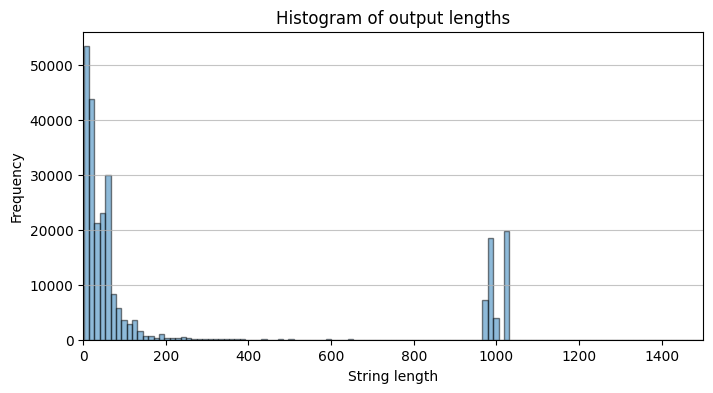

In [19]:
# Let's check the length of this datasets
import matplotlib.pyplot as plt
text_column = 'output'
lengths = [len(text.strip()) for text in dataset[text_column]]
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=500, edgecolor='black', alpha=0.5)
plt.title('Histogram of output lengths')
plt.xlabel('String length')
plt.ylabel('Frequency')
plt.xlim(0,1500)
plt.grid(axis='y', alpha=0.75)
plt.show()

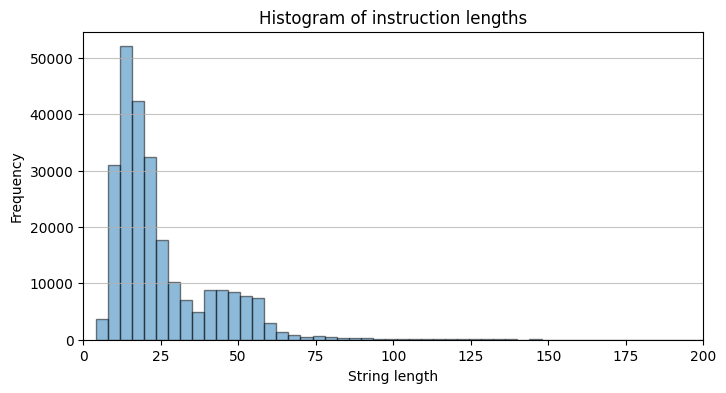

In [20]:
text_column = 'instruction'
lengths = [len(text.strip()) for text in dataset[text_column]]
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=500, edgecolor='black', alpha=0.5)
plt.title('Histogram of instruction lengths')
plt.xlabel('String length')
plt.ylabel('Frequency')
plt.xlim(0,200)
plt.grid(axis='y', alpha=0.75)
plt.show()

# 3. Finetuning and LoRA (Low-Rank Adaptation)

In order to be able to train the model better, I did not choose to train the model in Kaggle, but completed the training on 1 * A800 GPU.

Here are my training parameters:

```shell
--lora_r 128 \
--lora_alpha 256 \
--lora_dropout 0.1 \
--max_length 768 \
--num_train_epochs 3 \
--per_device_train_batch_size 1 \
--per_device_eval_batch_size 1 \
--gradient_accumulation_steps 64 \
--logging_steps 10 \
--save_steps 200 \
--eval_steps 200 \
--save_total_limit 3 \
--learning_rate 1e-5 \
--lr_scheduler_type cosine
```


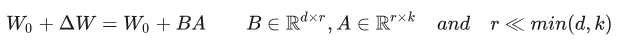

In [21]:
!pip install trl peft -q

/opt/conda/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


## 3.1. Dataset processing and prepare

In [22]:
from datasets import Dataset
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq, TrainingArguments, Trainer, GenerationConfig
from peft import LoraConfig, TaskType, get_peft_model
import argparse
import torch
from datasets import load_dataset

class args:
    model_path_or_name="/kaggle/input/gemma-2/transformers/gemma-2-9b-it/2"
    save_path="gemma-2-9b-lora"
    max_length=512
    lora_r=8
    lora_alpha=16
    lora_dropout=0.05
    batch_size=4
    per_device_train_batch_size=1
    logging_steps=5
    eval_steps=10
    save_steps=10
    num_train_epochs=2
    learning_rate=1e-4
    save_total_limit=1
    per_device_eval_batch_size=1
# parser.add_argument('--train_path', type=int, default=1e-5, help='')



In [23]:

tokenizer = AutoTokenizer.from_pretrained(args.model_path_or_name)
tokenizer.pad_token_id = tokenizer.eos_token_id
tokenizer.padding_side = 'right'
train_path = ['/kaggle/input/ancient-chinese-data-by-shiner/ancient_chinese_selected.json']
ds = load_dataset("json", data_files=train_path, split='train')
ds = ds.shuffle(42).select(range(int(200))) # We only use small part of dataset to implenment the training pipeline

def process_func(example):
    '''
    Gemma formatting:
    ```
    <start_of_turn>user
    knock knock<end_of_turn>
    <start_of_turn>model
    who is there<end_of_turn>
    ```
    Rel: https://ai.google.dev/gemma/docs/formatting
    '''
    MAX_LENGTH = args.max_length    
    input_ids, attention_mask, labels = [], [], []
    # Firstly, we concat the instruction and output together, and apply the prompt formatting of gemma.
    instruction = tokenizer(f"<bos><start_of_turn>user\n{example['instruction'] + example['input']}<end_of_turn>\n<start_of_turn>model\n", add_special_tokens=False) 
    response = tokenizer(f"{example['output']}<end_of_turn>\n", add_special_tokens=False)
    # Secondly, we use tokenizer to tokenize the sentence into input_ids, attention_mask and labels
    input_ids = instruction["input_ids"] + response["input_ids"] + [tokenizer.pad_token_id]
    attention_mask = instruction["attention_mask"] + response["attention_mask"] + [1]  # Because the eos token we also have to pay attention to, so append [1]
    labels = [-100] * len(instruction["input_ids"]) + response["input_ids"] + [tokenizer.pad_token_id]  # We only care about the part of the model output, so for the part of the model output by the user, we fill in [-100], 
                                                                                                        # so that when calculating the loss, only the loss of the model output needs to be calculated.
    # cut the query according to max length
    if len(input_ids) > MAX_LENGTH: 
        input_ids = input_ids[:MAX_LENGTH]
        attention_mask = attention_mask[:MAX_LENGTH]
        labels = labels[:MAX_LENGTH]
    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


tokenized_id = ds.map(process_func, remove_columns=ds.column_names)
# split the dataset into train dataset and test dataset
tokenized_id = tokenized_id.shuffle(42)
tokenized_id = tokenized_id.train_test_split(0.05, seed=42) 
train_id, test_id = tokenized_id['train'], tokenized_id['test']


print('whole sentence\n', tokenizer.decode(train_id[0]['input_ids']))
print()
print('label:\n', tokenizer.decode(list(filter(lambda x: x != -100, train_id[0]["labels"]))))



Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

whole sentence
 <bos><start_of_turn>user
上联：胜揽澎园，人文荟蔚千秋韵
下联：<end_of_turn>
<start_of_turn>model
情倾古建，风物咸宜满目春<end_of_turn>
<eos>

label:
 情倾古建，风物咸宜满目春<end_of_turn>
<eos>


## 3.2. LoRA Overview
Paper: https://arxiv.org/abs/2106.09685

![lora.png](https://www.helloimg.com/i/2024/12/26/676d49c13e996.png)

**LoRA (Low-Rank Adaptation) Fine-tuning** is a parameter-efficient method for adapting large pre-trained models to specific downstream tasks. 

Unlike full fine-tuning, which updates all parameters of the model, LoRA introduces trainable rank-decomposition matrices that modify the weights of a pre-trained model with a significantly smaller number of parameters.

As in the image below, suppose the full parameters are a matrix with $d*d$ and the parameter quantity is $d*d$, while the LoRA training parameter is two smaller matrices A and B with a parameter quantity of $2*d*r$. **If $d=2048$, $r=32$, the trainable parameter became $1.5626\%$ of the full parameter.**


## 3.3. Advantages
- 1. Reduces computational requirements. With this technique, we can easily train our LLM models on GPUs with smaller GPU memory.
- 2. Faster training and deployment. 
- 3. Maintains the model's original capabilities while adding domain-specific skills.

## 3.4. Advanced Technique
Paper: https://arxiv.org/abs/2305.14314

A more advanced and efficient method of parameter fine-tuning is Quantized Low-Rank Adaptation (**QLoRA**).

Relationship with LoRA:
Both QLoRA and LoRA use a low-rank adaptation technique, which significantly reduces the number of parameters that need to be fine-tuned by decomposing the parameter matrix into the product of two low-rank matrices.

Advantages of QLoRA: QLoRA introduces quantization technology on the basis of LoRA, which further reduces memory usage and computing resource consumption.

## 3.5. LoRA via Python

Implementing LoRA via Python has become very convenient, we just need to have some important libraries ready: transformers, peft, accelerate or deepspeed. 

At the same time, we also need to understand the key parameters of LoRA: 
- **lora_r**: refers to the rank in LoRA, which determines the size of the low-rank matrix.If lora_r set to 128 means that the low-rank matrix with rank 128 will be used to train the model.
- **lora_alpha**: scaling factor for LoRA adaptation. This parameter affects the update speed of the low-rank matrix. In general lora_alpha set to twice as much as lora_r.
- **lora_dropout**：the parameter used to prevent overfitting controls the dropout rate of LoRA's low-rank matrix.

If you are interested in the mathematical principles and derivation of LoRA, be sure to read the [**paper**](https://arxiv.org/abs/2305.14314): 


**Now let's start training our models with LoRA!**


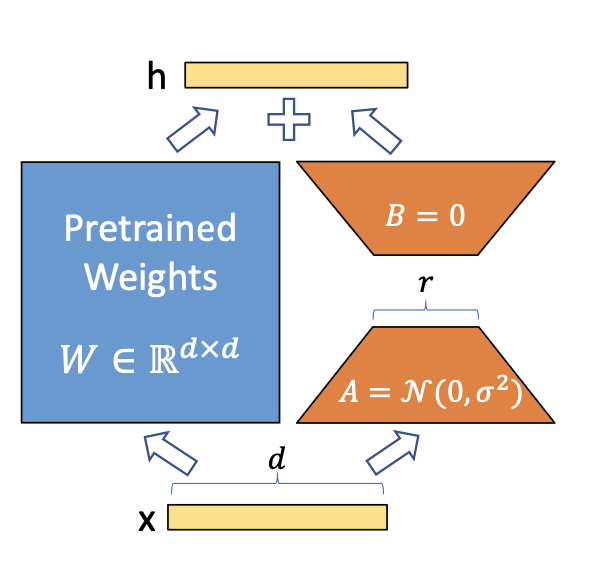
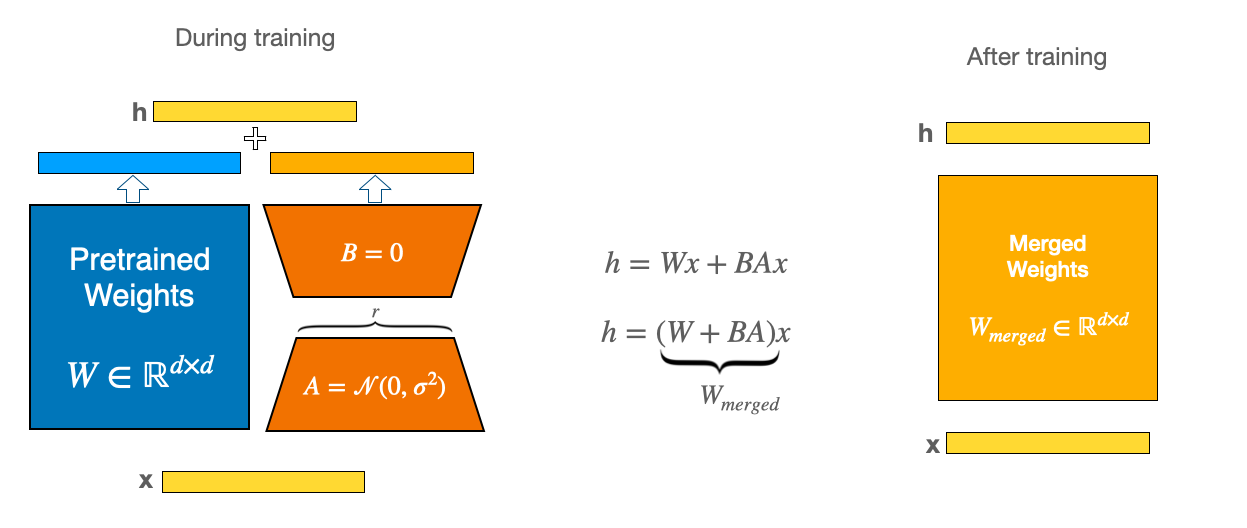

In [24]:
# We load the model at the very beginning of this notebook, so we don't have to load it again

# lora config
config = LoraConfig(
    task_type=TaskType.CAUSAL_LM, 
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", 'gate_proj', 'up_proj', 'down_proj'],
    inference_mode=False, # turn on train mode
    r=args.lora_r, # lora_r: refers to the rank in LoRA 
    lora_alpha=args.lora_alpha, # lora_alpha: scaling factor for LoRA adaptation
    lora_dropout=args.lora_dropout# lora_dropout：the parameter used to prevent overfittin
)

peft_model = get_peft_model(model, config) # get lora model by PEFT

print(peft_model.print_trainable_parameters()) # print trainable parameters of lora model


trainable params: 10,383,360 || all params: 2,624,725,248 || trainable%: 0.3956
None


In [25]:
# train config
train_args = TrainingArguments(
    output_dir=args.save_path,
    per_device_train_batch_size=args.per_device_train_batch_size,
    per_device_eval_batch_size=args.per_device_eval_batch_size,
    gradient_accumulation_steps=max(int(args.batch_size // args.per_device_train_batch_size), 1),
    logging_strategy='steps',
    logging_steps=args.logging_steps,
    num_train_epochs=args.num_train_epochs,
    # save_steps=args.save_steps,
    # eval_strategy='steps',
    # eval_steps=args.eval_steps,
    learning_rate=args.learning_rate,
    lr_scheduler_type='linear',
    warmup_ratio=0.05,
    # bf16=True, # If you have a new GPU, you should use bf16=True
    fp16=True,
    # save_total_limit=args.save_total_limit,
    report_to='none',
)


trainer = Trainer(
    model=peft_model,
    args=train_args,
    train_dataset=train_id, 
    # eval_dataset=test_id,
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, padding=True),
)

In [26]:
trainer.train()

# trainer.save_model(args.save_path)

Step,Training Loss
5,5.884000
10,5.158800
15,4.766000
20,4.768300
25,4.437100
30,4.551400
35,4.132900
40,4.958900
45,4.322900
50,4.398900


TrainOutput(global_step=94, training_loss=4.342597159933536, metrics={'train_runtime': 105.0803, 'train_samples_per_second': 3.616, 'train_steps_per_second': 0.895, 'total_flos': 365305472040960.0, 'train_loss': 4.342597159933536, 'epoch': 1.9789473684210526})

# 4. Testing the Fine-Tuned Model

We will test the Gemma2-2b and Gemma2-9b models I trained on my own device, respectively, using similar test data as in the 1st section.

Then, I also found a list that focused on the ability of large language models in ancient Chinese, tested the effect of Gemma2-9b-sft-lora on this list, and was pleasantly surprised to find that **the model we trained surpassed the native Gemma2-9b in some metrics, and far surpassed the capabilities of ChatGPT-3.5!**

# 4.1. Gemma 2 b

Load the finetuned model where I fine tuned on my device: Gemma 2 2b

In [27]:
# load the finetuned model where I fine tuned on my device: Gemma 2 2b
from peft import PeftModel
model_name_or_path = "/kaggle/input/gemma-2/transformers/gemma-2-2b-it/2"
lora_adopter_path = "/kaggle/input/gemma-2-2b-acnbot-lora/transformers/v1/1/gemma-2-2b-acnbot-lora"
# merge the adopter weights into orginal model
fine_tuned_model = PeftModel.from_pretrained(
        model,
        lora_adopter_path,
        torch_dtype=torch.float16,
)

### Translation of ancient Chinese idioms

In [28]:
# lets test the model we trained
text = "螳螂捕蝉，黄雀在后是什么意思？" # the instruction in English: Idiom Definition: 【The Idiom】\n Meaning:
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, fine_tuned_model)
print('\n**********generated_text**********\n')
# the output in English: 
# It is a metaphor that one must be well prepared before doing something in order to succeed.
# Idiom source: None
print(generated_text)

/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `-1.0` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `40` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



**********generated_text**********

比喻人做事，要先做好准备，才能成功。
成语出处：无


### Translation of ancient Chinese literature: from ancient Chinese to modern Chinese

In [29]:
text = "无始曰： 弗知之深而知之浅，弗知内而知之外，弗知精而知之粗。\n帮我翻译成现代文" # the instruction in English: 【The Ancient Chinese】\n Translate this sentence into modern Chinese.
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, peft_model)
print('\n**********generated_text**********\n')
# the output in English: Wu Shi said: If you don’t know the depth and shallowness, if you don’t understand the inside and outside, if you don’t understand the subtle, you won’t know the coarseness.
print(generated_text)


**********generated_text**********

无始说： 不知道深浅，不了解内外，不了解精微，就不知道粗糙。


### Translation of ancient Chinese literature with CoT.

In [30]:
text = "无始曰： 弗知之深而知之浅，弗知内而知之外，弗知精而知之粗。\nTranslate into Chinese Simplified Chinese and English" # the instruction in English: 【The Ancient Chinese】\n Translate this sentence into modern Chinese.
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, peft_model)
print('\n**********generated_text**********\n')
# the output in English: Wu Shi said: If you don’t know the depth and shallowness, if you don’t understand the inside and outside, if you don’t understand the subtle, you won’t know the coarseness.
print(generated_text)


**********generated_text**********

 Simplified Chinese: 无始说： 不知道深浅，不了解内外，不了解精粗。
English: Wu Shi said: I don't know how deep or shallow it is, I don't understand the inside and outside, and I don't understand the fine and the coarse.


### Ancient Chinese couplet generation

In [31]:
text = "上联：速造林，快育林，广护林，绿茵似海\n下联：" # the instruction in English: Upper Scroll of couplet: 【Neatly arranged ancient Chinese Couplet】\n Lower Scroll of couplet:
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, peft_model)
print('\n**********generated_text**********\n')
# the output in English: Long-term governance of the country, long-term governance of the people, broad governance of the people, peace and happiness for the people
print(generated_text)


**********generated_text**********

长治国，长治民，广治民，安民乐民


### Ancient Chinese poems generation

In [32]:
text = "以夏天为主题写一首诗" # the instruction in English: Topic: Summer. Make a Ancient Chinese Poetry
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer, gemma_formatting_text, peft_model)
print('\n**********generated_text**********\n')
# the output in English: The heat is all over the sky, the sun is shining brightly. The trees are green and the flowers are about to bloom. The wind blows the flowers away, the rain moistens the grass. The fields are vast, the water is clear. Birds are singing, insects are chirping. People want to rest, and the sky wants to rest.
print(generated_text)


**********generated_text**********

暑气满天，日照灼灼。绿树欲滴，花开欲飞。风吹花落，雨润草生。田野一片，水波清澈。鸟鸣声声，虫语声声。人欲休休，天欲休休。


## 4.1. Conclusion of Trained Gemma-2 2b
After training, we can see that the model's capabilities have improved significantly.
- **The model rarely outputs English under the input is Chinese;**
- **The model is better able to follow instructions in Chinese and Chinese;**
- **The model has better comprehension and generation ability for key characters such as ancient Chinese literature, ancient Chinese poetry and ancient Chinese couplets.** It is evident that the ancient poems and couplets generated by the model meet their criteria: **the same structure and the same theme**

## 4.2. Gemma2 9b (Int 8)

**Limited by the GPU memory, I load the Gemma 9B model in int8 quantization.**

In [33]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

model_id = "/kaggle/input/m/judith007/gemma-2/transformers/gemma-2-9b/1/gemma-2-9b-ancient-chinese"

tokenizer_9b = AutoTokenizer.from_pretrained(model_id)
model_9b_8bit = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=BitsAndBytesConfig(load_in_8bit=True), device_map="auto")

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

### Identity

In [34]:
text = "Who are you? Are you ChatGPT?" 
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print('\n**********generated_text**********\n')
print(generated_text)

/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `-1.0` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `40` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



**********generated_text**********

I am ACNBot, an AI assistant developed by Shiner. How can I assist you today?



### Ancient Chinese couplet generation


In [35]:
text = "写一个迎新年的对联" # the instruction in English: Topic: New Year. Make a Ancient Chinese Couplet
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print('\n**********generated_text**********\n')
# the output in English: The jade rabbit welcomes the spring with great joy, and the golden monkey brings endless happiness to the new year.
print(generated_text)


**********generated_text**********

玉兔迎春喜满堂，金猴送岁乐无穷。



### Translation of ancient Chinese literature：from modern Chinese to ancient Chinese

In [36]:
text = "写一个 关于一个人卖马，他的马很美丽，然后一个读书人路过看到他的马，给他的马写了一首诗 的古文" 
# the instruction in English: Write an ancient text about a person selling a horse, whose horse is very beautiful, and then a scholar passing by sees the horse and writes a poem for it.
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
# the output in English: A person selling a horse, whose horse is very beautiful, and then a scholar passing by sees the horse and writes a poem for it.
print('\n**********generated_text**********\n')
print(generated_text)


**********generated_text**********

有贩马者，其马甚美，读书人过见之，为马作诗云：天马非天马，有骨无神气。神气在人，人去神去。



### Ancient Chinese poems generation

In [37]:
text = "写一个关于感谢的诗" # the instruction in English: Topic: Grateful. Make a Ancient Chinese Poetry
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print('\n**********generated_text**********\n')
# output in English: A thought of kindness can lead to a thousand eons of karma. Why should I repay kindness in three lifetimes? If there is no repayment now, there will be no future. If there is repayment now, there will be a future.
print(generated_text)


**********generated_text**********

一念慈心万劫缘，三生报德今何因。只今无报无来日，只今有报有来身。



In [38]:
text = "写一个人工智能的诗" # the instruction in English: Topic: Artificial Intelligence. Make a Ancient Chinese Poetry
gemma_formatting_text = get_text_in_gemma_format(text)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print('\n**********generated_text**********\n')
# output in English: Unintentional is born in the machine, everything is in the program. Poetry is like people's joy and anger, every word is true.
print(generated_text)


**********generated_text**********

无心生于机中，万象尽在程式。诗思如人有喜怒，字字皆是真情。



## 4.3. ACLUE: Ancient Chinese Language Understanding Evaluation Benchmark 

https://github.com/isen-zhang/ACLUE.git

At present, there are very few evaluation sets and rankings to evaluate the ancient Chinese ability of large models, and it also took me a long time to find this evaluation set to evaluate the trained model.

The Ancient Chinese Language Understanding Evaluation (ACLUE) is an evaluation benchmark focused on ancient Chinese language comprehension. It aims to assess the performance of large-scale language models on understanding ancient Chinese. The benchmark comprises 15 tasks spanning various domains, including **lexical, syntactic, semantic, Inference, and knowledge**. So this set of evaluations is very comprehensive, and I think it can fairly evaluate the model's ability in ancient Chinese.

The test results. You are welcome to download my model or using my dataset to train a model, and then run the model in this task and see the performce of the model on ACLUE.

| model     | Lexical | Syntactic | Semantic | Inference | Knowledge |
|-----------|---------|-----------|----------|-----------|-----------|
| [ChatGLM2-6B](https://huggingface.co/tiiuae/falcon-40b)   |   34.00   |   38.00   |   39.90   |   36.53   |   38.85   |
| [ChatGPT](https://openai.com/chatgpt)                     |   34.53   |   43.00   |   36.40   |   41.23   |   33.61   |
| [BLOOMZ-7B](https://github.com/bigscience-workshop/xmtf)  |   34.40   |   32.20   |   43.70   |   30.19   |   37.31   |
| [ChatGLM-6B](https://github.com/THUDM/GLM-130B)           |   32.80   |   36.60   |   30.50   |   34.59   |   32.81   |
| [Falcon-40B](https://huggingface.co/tiiuae/falcon-40b)    |   30.13   |   32.60   |   34.30   |   33.65   |   30.78   |
| [Baichuan-7B](https://github.com/baichuan-inc/baichuan-7B)|   28.00   |   32.20   |   32.80   |   30.40   |   34.56   |
| [LLaMA-65B](https://github.com/facebookresearch/llama)    |   28.33   |   33.00   |   29.60   |   29.10   |   27.56   |
| [MOSS-SFT-16B](https://github.com/OpenLMLab/MOSS)         |   28.00   |   24.00   |   27.50   |   27.42   |   24.34   |
| Random                                                    |   25.00   |   25.00   |   25.00   |   25.00   |   25.00   |
| **gemma-2-2b-sft-lora**                                   |   31.47   |   34.00   |   29.10   |   35.56   |   30.15   |
| **gemma-2-9b-sft-lora**                                   |   44.13   | **58.20** |   45.30   |   38.43   | **39.60** |
| gemma-2-9b                                                | **45.80** |   52.40   | **51.40** | **47.22** |   36.26   |

We can clearly see that trained Gemma-2-9b significantly outperforms the original Gemma-2-9b in **Syntactic** and **Knowledge**. This shows that our fine-tuning has greatly improved the fluency of Gemma in ancient Chinese and even modern Chinese, and can generate better content for ancient poems, ancient documents and couplets.

# 5. RAG for Chinese idioms (30k new dataset)

RAG, or Retrieval-Augmented Generation, is an artificial intelligence technology that combines information retrieval technology with language generation models.
The working principle of RAG can be summarized in three steps: "Retrieval, Augmentation, Generate":

- **Retrieval**: Obtain relevant information from the plug-in knowledge base based on the user's query content. Specifically, the user's query is converted into vectors through the embedding model to be compared with the knowledge-related vectors stored in the vector database. Through similarity search, find the top K data that best matches from the vector database.
- **Augmentation**: Embed the user's query content and retrieved knowledge into a preset prompt template to form an enhanced prompt.
- **Generate**: Generate the desired output by feeding the search-enhanced prompt content into a large language model (LLM).


The interpretation of Chinese idioms often requires a high degree of accuracy, so I think RAG can help our Gemma model output very credible results. **Therefore, I also created a dataset of 30k Chinese idioms.**

But just to make a RAG example in this notebook, I'm only using 2000 of them to see the effect.

In [39]:
with open("/kaggle/input/chinese-idioms-dictionary-by-shiner/chinese_idioms_for_rag.json", 'r') as fp:
    corpus = json.load(fp)[:2000]
corpus = [item.replace('\n', '') for item in corpus]

In [40]:
from FlagEmbedding import FlagModel
import faiss
import numpy as np
# Make the corpus embedding
emb_model = FlagModel('BAAI/bge-small-zh-v1.5',
                  query_instruction_for_retrieval="为这个句子生成表示以用于检索相关文章：", # the instruction in English: retrieve related articles for Generation 
                  use_fp16=True)
embeddings = emb_model.encode(corpus)
# Make index of the corpus by faiss
index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)

tokenizer_config.json:   0%|          | 0.00/367 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/439k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/776 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/95.8M [00:00<?, ?B/s]

----------using 2*GPUs----------


Inference Embeddings:   0%|          | 0/4 [00:00<?, ?it/s]/opt/conda/lib/python3.10/site-packages/torch/nn/parallel/parallel_apply.py:79: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.device(device), torch.cuda.stream(stream), autocast(enabled=autocast_enabled):
Inference Embeddings: 100%|██████████| 4/4 [00:01<00:00,  2.88it/s]


In [41]:
def retrieval(query, top_k=5):
    q_embedding = emb_model.encode_queries([query])
    D, I = index.search(q_embedding, top_k)
    res = np.array(corpus)[I]
    return res.tolist()[0]

def make_rag_pipeline(model, tokenizer, query, top_k_retrieval, print_prompt=True):
    '''
    RAG Prompt in English:
    ```
    You are a professional scholar of ancient Chinese literature, and your task is to answer questions from users whenever possible according to ##Referenced information#.
    ##Referenced information##:
    {retrieval_docs}
    The user's query is: {user_input}
    Your answer:
    ```
    '''
    rag_prompt = """你是一个专业的古汉语文学家，你的任务是根据##参考的信息##尽可能回答用户的提问。

##参考的信息##：
{retrieval_docs}

用户的查询为：{user_input}
你的回答："""
    # Retrieval: retrieve the documents according to user's query.
    retrieval_docs = retrieval(query, top_k_retrieval)
    retrieval_docs = '\n'.join(retrieval_docs)
    # Augmentation: put the user query and retrieved documents into rag prompt.
    rag_prompt = rag_prompt.format(
        retrieval_docs=retrieval_docs,
        user_input=query
    )
    if print_prompt:
        print('*********retrieval_docs*********')
        print(retrieval_docs.replace('\n','<n>'))
        print('*********rag_prompt*********\n')
        print(rag_prompt)
    # Generate: put the prompt into Gemma to generate reliable results
    gemma_formatting_text = get_text_in_gemma_format(text)
    generated_text = get_gemma_output(tokenizer, rag_prompt, model)
    return generated_text

 ### Interpretation of Chinese idioms without RAG

It is clear that the model's interpretation of Old Chinese idioms is wrong. This indicates that there is a problem with the output of the model, and when the text generated by the model does not follow the original text (Faithfulness) or factualness, this phenomenon is called LLM hallucination. Next, we solve this problem with the RAG method.

In [42]:
query = "以公灭私是什么意思啊？" # instruction in English: What does it mean 【Ancient Chinese idioms】?
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
# output in English:
# Refers to handling and solving problems with fairness as the standard and excluding selfishness.
# Idiom source: None
print(generated_text)

指处理问题、解决问题以公正为标准，排除私心。
成语出处：无



In [43]:
query = "帮我查一下手脚无措是什么意思" # instruction in English: Help me find out what it means 【Ancient Chinese idioms】
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
# output in English:
# It means that there are disasters outside and troubles inside, and the situation is very difficult and there is nothing one can do. Same as being at a loss.
# Idiom source: None
print(generated_text)

形容外有灾祸，内有祸患，处境十分困难，无能为力。同手足无措”。
成语出处：无



 ### Interpretation of Chinese idioms with RAG

 We can clearly see that through RAG, the large model clearly outputs accurate answers, eliminating the LLM hallucination problem in the above cases.

In [44]:
query = "以公灭私是什么意思啊？" # instruction in English: What does it mean 【Ancient Chinese idioms】?
generated_text = make_rag_pipeline(model_9b_8bit, tokenizer_9b, query, top_k_retrieval=3, print_prompt=True)
print('*********generated text*********')
# output in English:
# It points out that one should be public-minded and put aside personal feelings or grudges.
# The source of the idiom: "Shu·Zhou Guan" uses the public to destroy private interests, and the people will accept them. "Cai Chenji preached the justice of the world and eliminated one's personal feelings."
print(generated_text)

*********retrieval_docs*********
以公灭私成语释义：指出以公心而去掉个人的私情或恩怨。成语出处：《书·周官》以公灭私，民其允怀。”蔡沈集传以天下之公理，灭一己之私情。”<n>公平无私这句话的意思是什么？办事公平，没有私心。成语出处：《战国策·秦策》法令至行，公平无私。”<n>假道灭虢是什么意思？假借；道道路；虢春秋时诸侯国，在今山西平陆及河南三门峡一带。泛指用借路的名义而灭亡这个国家。成语出处：《左传·僖公二年》晋荀息请以屈产之乘，与垂棘之璧，假道于虞以伐虢。”
*********rag_prompt*********

你是一个专业的古汉语文学家，你的任务是根据##参考的信息##尽可能回答用户的提问。

##参考的信息##：
以公灭私成语释义：指出以公心而去掉个人的私情或恩怨。成语出处：《书·周官》以公灭私，民其允怀。”蔡沈集传以天下之公理，灭一己之私情。”
公平无私这句话的意思是什么？办事公平，没有私心。成语出处：《战国策·秦策》法令至行，公平无私。”
假道灭虢是什么意思？假借；道道路；虢春秋时诸侯国，在今山西平陆及河南三门峡一带。泛指用借路的名义而灭亡这个国家。成语出处：《左传·僖公二年》晋荀息请以屈产之乘，与垂棘之璧，假道于虞以伐虢。”

用户的查询为：以公灭私是什么意思啊？
你的回答：
*********generated text*********
指出以公心而去掉个人的私情或恩怨。
成语出处：《书·周官》以公灭私，民其允怀。”蔡沈集传以天下之公理，灭一己之私情。”



In [45]:
query = "帮我查一下手脚无措是什么意思" # instruction in English: Help me find out what it means 【Ancient Chinese idioms】
generated_text = make_rag_pipeline(model_9b_8bit, tokenizer_9b, query, top_k_retrieval=3, print_prompt=False)
print('*********generated text*********')
# output in English:
# Describes panic or inability to cope. Same as being at a loss.
# Idiom source: None
print(generated_text)

*********generated text*********
形容举动慌张，或无法应付。同手足无措”。成语出处：无



### Conclusion for RAG

By using RAG technology, Gemma2 successfully dispels the LLM illusion and generates reliable and accurate answers to the user's requests for ancient Chinese idioms. This is due to two key aspects:
1. Gemma2-9b (ACNBot) trained by us, **has a stronger understanding of the answers to the instruction in Chinese, and the output is also in Chinese.**
2. **The recall ability of the recall model ensures the accuracy of the recall knowledge.** If we want to further improve the effectiveness of RAG, we can use stronger models and train recall models.

# 6. Few-shot Prompting for Semantic Classification of Ancient Chinese Idioms

In the study of ancient Chinese idioms, the emotional tendency of the idioms is a very important research topic.

Ancient Chinese idioms have emotional tendencies, which can be either **commendatory (positive), derogatory (negative), or neutral.**

I will try to use the **few-shot prompting** to make the trained model output **reliable semantic classification results.**

In [46]:
# For your convenience, I show you a few-shot prompt in English as follow, but I will eventually use the prompt in Chinese.
few_shot_prompt_english = """You are an expert in ancient Chinese. Your task is to identify whether the given idiom is positive, negative or neutral.

Examples:
The Idiom: 三心二意
Semantic: Negative

The Idiom: 兴高采烈
Semantic: Positive

The Idiom: {idiom}
Semantic: """

few_shot_prompt_chinese = """你是古汉语专家。你的任务是判断给定的成语是肯定的、否定的还是中性的。

示例：
成语：三心二意
语义：贬义

成语：兴高采烈
语义：褒义

成语：智勇双全
语义：褒义

成语：鱼龙混杂
语义：贬义

成语：七上八下
语义：中性

成语：{idiom}
语义："""

In [47]:
test_idiom = '蛇鼠一窝' # instruction in English: Snakes and rats in the same nest. Means bad guys easily gather together. It is a derogatory (negative) idiom
query = few_shot_prompt_chinese.format(idiom=test_idiom)
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
# output in English: Negative
print(generated_text)

贬义



In [48]:
test_idiom = '合家团圆' # instruction in English: Family Reunion. Means The families are reunited. It is a commendatory (positive) idiom
query = few_shot_prompt_chinese.format(idiom=test_idiom)
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
# output in English: Positive
print(generated_text)

褒义



**In this subsection, I show that the trained Gemma2 provides accurate and reliable semantic classification results for ancient Chinese idioms through few-shot prompting.**

# 7. Robustness of Trained Model

We want to test the robustness of the model after fine-tuning Gemma2, so we test several common languages to test its robustness.

We can clearly see that after training, Gemma2-9b still has strong robustness, and its responses to other languages are also very fluent and reliable.

### English

In [49]:
query = "Please help me write a text to promote coats. Describe the material and advantages of the coat in detail. Use some tempting words to sell the coat."
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print(generated_text)

🍂 The autumn wind is getting stronger, and the temperature difference between morning and evening is getting bigger. Don't forget to add clothes! 🍂

✨ Our new autumn coat is here! ✨

🧥 Fabric: Selected high-quality imported wool, soft and skin-friendly, not easy to pilling, wear-resistant and durable, keeping warm and comfortable all day long.

🧥 Design: Classic lapel design, simple and elegant, versatile and stylish. The tailored version is tailored to your body, showing your figure and temperament.

🧥 Features: Exquisite button design, smooth and delicate, easy to wear and take off. The lining is made of high-quality satin, which is smooth and comfortable, and does not irritate the skin.

🧥 Advantages: Windproof, warm, stylish and versatile, suitable for various occasions.

Don't miss this opportunity to upgrade your autumn wardrobe!



### Japanese

In [50]:
query = "東京について紹介してください。" # instruction in English:  Please introduce Tokyo.
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print(generated_text)
# output in English: Tokyo is the capital of Japan and a city located in the Tokyo metropolitan area, a special ward of the metropolitan area. Tokyo is the political, economic and cultural center of Japan and one of the world's leading megacities.

東京は、日本国の首都であり、東京都の特別区である特別区東京に位置する都市です。東京は、日本の政治、経済、文化の中心地であり、世界有数のメガシティです。



### Korean

In [51]:
query = "샌드위치를 만들려면 어떤 재료가 필요합니까?" # instruction in English:  What ingredients do you need to make a sandwich?
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print(generated_text)
# output in English: There are many different ingredients for making sandwiches. The most basic ingredients are bread and fillings. There are many different types of bread, such as white, whole wheat, and grain, and the fillings include ham, cheese, eggs, and vegetables. To make the sandwich more delicious, it is also good to eat it with sauce.

 샌드위치를 만드는 재료는 매우 다양합니다. 가장 기본적인 재료는 빵과 속재료입니다. 빵은 흰색, 통밀, 곡물 등 다양한 종류가 있으며, 속재료는 햄, 치즈, 계란, 야채 등이 있습니다. 샌드위치를 더 맛있게 만들려면 소스를 곁들여 먹는 것도 좋습니다.



### French

In [52]:
query = "Veuillez expliquer brièvement pourquoi Paris est le centre de la mode." # instruction in English: Please briefly explain why Paris is the center of fashion.
gemma_formatting_text = get_text_in_gemma_format(query)
generated_text = get_gemma_output(tokenizer_9b, gemma_formatting_text, model_9b_8bit)
print(generated_text)
# output in English :
# Paris is considered the center of fashion for several reasons:
# * **History and tradition:** Paris has a long and rich history of couture and design, dating back to the 17th century.
# * **World-renowned designers:** The city is home to many world-renowned designers, such as Chanel, Dior, Givenchy, Yves Saint Laurent, and Louis Vuitton.
# * **Fashion weeks:** Paris hosts two fashion weeks per year, which attract buyers, journalists, and celebrities from around the world.
# * **Cultural influence:** Paris is an influential cultural capital, and its fashion is often considered a symbol of style and elegance.
# * **Thriving fashion industry:** The city has a thriving fashion industry, with many ateliers, manufacturers, and distributors.

Paris est considéré comme le centre de la mode pour plusieurs raisons :

* **Histoire et tradition:** Paris possède une longue et riche histoire de couture et de design, remontant au 17ème siècle.
* **Créateurs de renommée mondiale:** La ville abrite de nombreux créateurs de renommée mondiale, tels que Chanel, Dior, Givenchy, Yves Saint Laurent et Louis Vuitton.
* **Semaines de la mode:** Paris accueille deux semaines de la mode par an, qui attirent des acheteurs, des journalistes et des célébrités du monde entier.
* **Influence culturelle:** Paris est une capitale culturelle influente, et sa mode est souvent considérée comme un symbole de style et d'élégance.
* **Industrie de la mode florissante:** La ville possède une industrie de la mode florissante, avec de nombreux ateliers, fabricants et distributeurs.



# 8. Conclusion

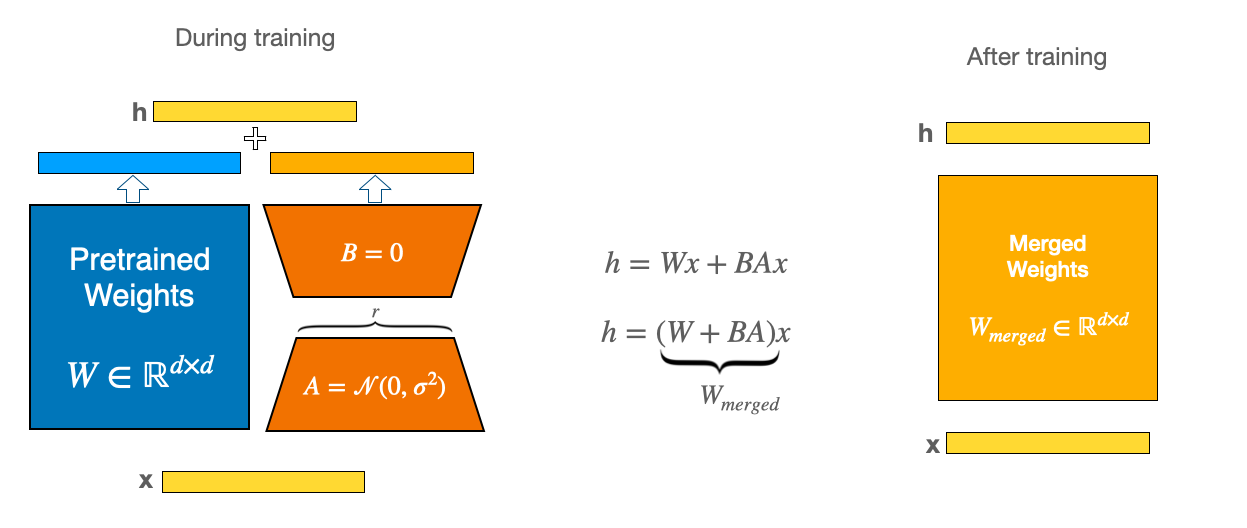

This project examines the application and potential of Gemma in ancient Chinese (Simplified) and Chinese culture. 
- Through collation and creation, this project contributed 252k high-quality datasets related to ancient Chinese and 30k high-quality data that can be used for ancient Chinese idioms RAG.
- At the same time, after careful data selection and training parameter adjustment, the problems of Chinese alignment ability (easy to generate English) and insufficient understanding of ancient Chinese on ancient Chinese (Chinese simplified) of Gemma2-9b were successfully solved. In the end, it surpassed ChatGPT-3.5 in the leaderboard of a public LLM ancient Chinese proficiency: Ancient Chinese Language Understanding Evaluation Benchmark (ACLUE), and also surpassed the native Gemma2-9b in some of the indicators
- This notebook showed the trained Gemma2-9b can be used in RAG for ancient Chinese idiom interpretion and Few-Shot Prompting in idiom semantic classification.
- The trained Gemma2 still maintains very good robustness and can maintain stable and reliable results for other languages.

**At the same time, I also appreciate whoever clicked and read this notebook, I hope it can be helpful to you.🤗**